# 3. Results and figures

Uses all files from notebook 2. All figures would be saved in `figures/`.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

pred = pd.read_csv("results/predictions.csv")
metrics = pd.read_csv("results/metrics.csv", header=[0, 1], index_col=0)
importance = pd.read_csv("results/importance.csv")
y = pred.band_gap
metrics.round(3)

MAE          RMSE            R2       
                                mean    std   mean    std   mean    std
model                                                                  
nn_composition+neighbours      0.409  0.020  0.536  0.022  0.515  0.036
rf_composition+neighbours      0.438  0.013  0.553  0.019  0.483  0.032
nn_composition                 0.445  0.017  0.574  0.019  0.443  0.038
rf_composition                 0.448  0.015  0.568  0.018  0.456  0.031
linear_composition+neighbours  0.554  0.016  0.677  0.013  0.227  0.023
linear_composition             0.564  0.012  0.683  0.011  0.214  0.023
mean_baseline                  0.656  0.006  0.771  0.005 -0.004  0.006

## 3.1 Which model is best? Does neighbour information improve the accuracy?

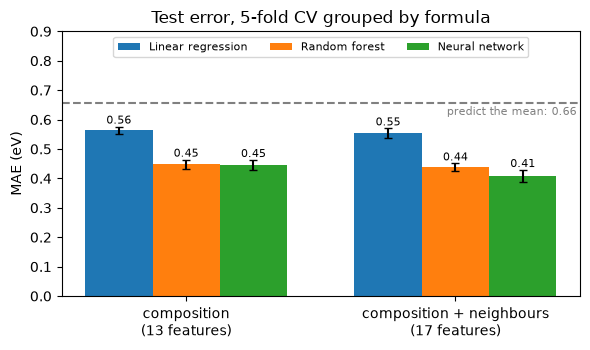

In [10]:
models = [("linear", "Linear regression", "tab:blue"),
          ("rf", "Random forest", "tab:orange"),
          ("nn", "Neural network", "tab:green")]
sets = ["composition", "composition+neighbours"]

plt.figure(figsize=(6, 3.6))
width = 0.25
for i, (key, label, color) in enumerate(models):
    mae = [metrics.loc[f"{key}_{s}", ("MAE", "mean")] for s in sets]
    std = [metrics.loc[f"{key}_{s}", ("MAE", "std")] for s in sets]
    x = np.arange(2) + (i - 1) * width
    plt.bar(x, mae, width, yerr=std, capsize=3, color=color, label=label)
    for xi, m, e in zip(x, mae, std):
        plt.text(xi, m + e + 0.01, f"{m:.2f}", ha="center", fontsize=8)
base = metrics.loc["mean_baseline", ("MAE", "mean")]
plt.axhline(base, ls="--", color="gray")
plt.text(1.45, base - 0.04, f"predict the mean: {base:.2f}", ha="right", color="gray", fontsize=8)
plt.xticks([0, 1], ["composition\n(13 features)", "composition + neighbours\n(17 features)"])
plt.ylabel("MAE (eV)")
plt.ylim(0, 0.9)
plt.legend(loc="upper center", ncol=3, fontsize=8)
plt.title("Test error, 5-fold CV grouped by formula")
plt.tight_layout()
plt.savefig("figures/fig3_model_comparison.png", dpi=200)
plt.show()

## 3.2 Predicted values compared with the real values

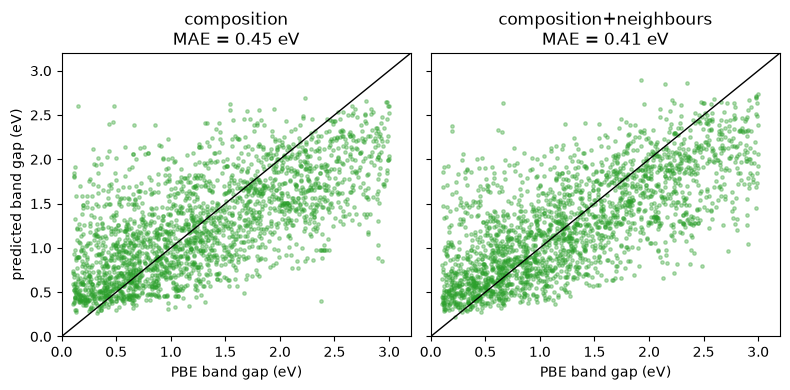

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharey=True)
for ax, s in zip(axes, sets):
    p = pred[f"nn_{s}"]
    ax.scatter(y, p, s=6, alpha=0.35, color="tab:green")
    ax.plot([0, 3.2], [0, 3.2], "k-", lw=1)
    ax.set_xlim(0, 3.2)
    ax.set_ylim(0, 3.2)
    ax.set_xlabel("PBE band gap (eV)")
    ax.set_title(f"{s}\nMAE = {np.abs(p - y).mean():.2f} eV")
axes[0].set_ylabel("predicted band gap (eV)")
plt.tight_layout()
plt.savefig("figures/fig4_parity.png", dpi=200)
plt.show()

In [12]:
# where are the errors? split by true gap
p = pred["nn_composition+neighbours"]
bins = pd.cut(y, [0.1, 0.5, 1.0, 2.0, 3.0], include_lowest=True)
pd.DataFrame({"n": y.groupby(bins, observed=True).size(),
              "MAE": (p - y).abs().groupby(bins, observed=True).mean(),
              "mean error (pred - true)": (p - y).groupby(bins, observed=True).mean()}).round(2)

,n,MAE,mean error (pred - true)
band_gap,,,
"(0.099, 0.5]",414,0.45,0.45
"(0.5, 1.0]",567,0.31,0.19
"(1.0, 2.0]",821,0.34,-0.11
"(2.0, 3.0]",505,0.59,-0.56


The model's predictions are inclined to the middle value: small band gaps are overestimated, while large band gaps are underestimated.

## 3.3 Can the model distinguish between different structures of the same compound?

Many chemical formulas correspond to multiple crystal structures. If only compositional features are used, the input for these structures becomes identical, forcing the model to produce the same prediction for each. By focusing on these specific chemical formulas, we subtract the mean band gap value (calculated for each formula) from the individual band gap values; we then investigate whether the differences in the model's predictions align with the actual observed differences.

776 materials in 309 formulas with more than one structure
composition               correlation = 0.00
composition+neighbours    correlation = 0.33


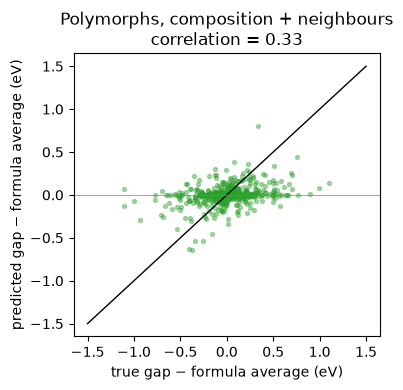

In [13]:
multi = pred.groupby("formula").filter(lambda t: len(t) > 1)
print(len(multi), "materials in", multi.formula.nunique(), "formulas with more than one structure")

dy = multi.band_gap - multi.groupby("formula").band_gap.transform("mean")
poly = {}
for s in sets:
    dp = multi[f"nn_{s}"] - multi.groupby("formula")[f"nn_{s}"].transform("mean")
    poly[s] = np.corrcoef(dy, dp)[0, 1] if dp.std() > 1e-6 else 0.0
    print(f"{s:25s} correlation = {poly[s]:.2f}")

dp = multi["nn_composition+neighbours"] - multi.groupby("formula")["nn_composition+neighbours"].transform("mean")
plt.figure(figsize=(4, 4))
plt.scatter(dy, dp, s=8, alpha=0.4, color="tab:green")
plt.plot([-1.5, 1.5], [-1.5, 1.5], "k-", lw=1)
plt.axhline(0, color="gray", lw=0.5)
plt.xlabel("true gap − formula average (eV)")
plt.ylabel("predicted gap − formula average (eV)")
plt.title(f"Polymorphs, composition + neighbours\ncorrelation = {poly['composition+neighbours']:.2f}")
plt.tight_layout()
plt.savefig("figures/fig5_polymorphs.png", dpi=200)
plt.show()

## 3.4 Which features does the network use?

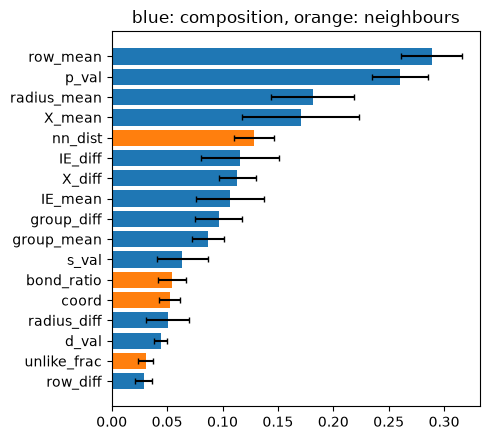

In [14]:
imp = importance.groupby("feature").mae_increase.agg(["mean", "std"]).sort_values("mean")
PAIR = ["nn_dist", "coord", "bond_ratio", "unlike_frac"]
colors = ["tab:orange" if f in PAIR else "tab:blue" for f in imp.index]

plt.figure(figsize=(5, 4.5))
plt.barh(imp.index, imp["mean"], xerr=imp["std"], color=colors, capsize=2)
plt.title("blue: composition, orange: neighbours")
plt.tight_layout()
plt.savefig("figures/fig6_importance.png", dpi=200)
plt.show()

## 3.5 Using the 5 networks to estimate uncertainty

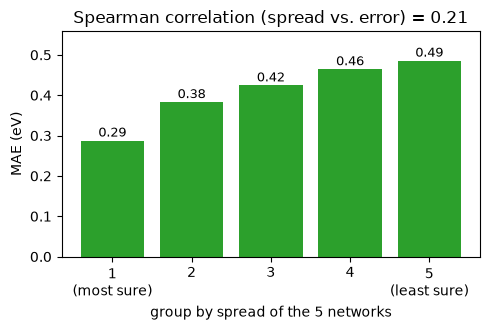

typical spread: [0.06, 0.1, 0.14, 0.18, 0.28]


In [15]:
err = (pred["nn_composition+neighbours"] - y).abs()
std = pred["nn_std_composition+neighbours"]
rho = spearmanr(std, err).correlation

groups = pd.qcut(std, 5, labels=["1\n(most sure)", "2", "3", "4", "5\n(least sure)"])
mae_by_group = err.groupby(groups, observed=True).mean()

plt.figure(figsize=(5, 3.4))
plt.bar(mae_by_group.index.astype(str), mae_by_group.values, color="tab:green")
for i, v in enumerate(mae_by_group.values):
    plt.text(i, v + 0.01, f"{v:.2f}", ha="center", fontsize=9)
plt.ylim(0, mae_by_group.max() * 1.15)
plt.xlabel("group by spread of the 5 networks")
plt.ylabel("MAE (eV)")
plt.title(f"Spearman correlation (spread vs. error) = {rho:.2f}")
plt.tight_layout()
plt.savefig("figures/fig7_uncertainty.png", dpi=200)
plt.show()
print("typical spread:", std.groupby(groups, observed=True).mean().round(2).tolist())

## 3.6 Summary 

In [16]:
m = lambda name: metrics.loc[name, ("MAE", "mean")]
best, comp = m("nn_composition+neighbours"), m("nn_composition")
print(f"materials: {len(pred)}, formulas: {pred.formula.nunique()}")
print(f"mean baseline MAE: {m('mean_baseline'):.3f}")
print(f"NN composition MAE: {comp:.3f}, NN composition+neighbours MAE: {best:.3f}")
print(f"improvement from neighbours: {100 * (comp - best) / comp:.1f}%")
print(f"NN R2: {metrics.loc['nn_composition+neighbours', ('R2', 'mean')]:.2f}")
print(f"within 0.5 eV: {100 * (err < 0.5).mean():.0f}%")
print(f"MAE most sure group: {mae_by_group.iloc[0]:.2f}, least sure: {mae_by_group.iloc[-1]:.2f}")

materials: 2307, formulas: 1840
mean baseline MAE: 0.656
NN composition MAE: 0.445, NN composition+neighbours MAE: 0.409
improvement from neighbours: 8.2%
NN R2: 0.52
within 0.5 eV: 69%
MAE most sure group: 0.29, least sure: 0.49
